
# Task 2: Exploratory Data Analysis (EDA)

## Project: Retail Sales Analysis

### 1. Introduction

Exploratory Data Analysis (EDA) is the process of examining, summarizing, and visualizing data to understand its main characteristics. It helps identify patterns, trends, relationships, and unusual observations before further analysis or predictive modelling.

In this project, we will analyze a retail sales dataset that contains information about transactions, products, customers, regions, discounts, sales, costs, and profits.

The analysis will use Python, Pandas, NumPy, Matplotlib, and Seaborn to explore the data through descriptive statistics and visualizations.

### 2. Objectives

The main objectives of this project are:

- Understand the structure and characteristics of the cleaned dataset.
- Calculate and interpret descriptive statistics.
- Analyze numerical distributions using histograms and KDE plots.
- Examine correlations between numerical variables.
- Compare sales performance across product categories, regions, and sales channels.
- Investigate monthly sales trends.
- Explore relationships between discounts, quantities, sales, and profits.
- Identify at least three actionable business insights.
- Develop evidence-based recommendations for improving retail performance.

### 3. Business Questions

This analysis aims to answer the following questions:

1. What does the distribution of retail sales look like?
2. Which product categories generate the highest total sales?
3. Which regions perform best and worst in terms of revenue?
4. How do sales change over time?
5. What relationships exist between sales, quantity, discounts, and profit?
6. How does performance differ across sales channels and customer segments?
7. What actions could the business take to improve sales and profitability?

### 4. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

The results will be summarized through statistical tables, visualizations, and business recommendations.


## 5. Import Libraries and Load the Dataset

The first step is to import the libraries required for data manipulation, numerical calculations, and visualization.

We will then load the cleaned dataset produced in Task 1. Using the cleaned dataset helps ensure that the EDA is performed on data that has already undergone initial quality checks and preparation.

The dataset will be inspected to understand its dimensions, column names, data types, and overall structure.


In [ ]:
#mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

DATA_PATH = Path("/content/drive/MyDrive/Week2Assign/retail_sales_cleaned.csv")
df = pd.read_csv(DATA_PATH)

# Convert date columns to datetime
for col in ["order_date", "ship_date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 11928
Number of columns: 21


,order_id,order_date,ship_date,store_id,region,customer_segment,product_id,product_name,product_category,quantity,unit_price,discount,promotion,sales,cost_price,shipping_cost,profit,payment_method,sales_channel,holiday_flag,order_status
0,ORD000001,2023-04-08,2023-04-10,ST101,north,consumer,P3001,Running Shoes,fashion,7.0,3022.96000,0.082,festival sale,19890.12,1610.25,5.960,8612.41,upi,in-store,0,returned
1,ORD000002,2025-04-28,2025-05-01,ST303,east,consumer,P5001,Skincare Kit,beauty & personal care,3.0,1351.45000,0.107,no promotion,4574.92,657.02,100.970,2502.89,cash,online,0,completed
2,ORD000003,2024-12-18,2024-12-18,ST401,west,consumer,P2003,Bedsheet Set,home & kitchen,5.0,1614.89000,0.072,no promotion,9323.44,756.38,27.900,5513.64,credit card,in-store,1,completed
3,ORD000004,2024-04-26,2024-04-26,ST501,central,consumer,P1002,Smartphone,electronics,3.0,6542.12375,0.192,no promotion,47721.03,13601.43,29.195,6874.41,cash,online,0,completed
4,ORD000005,2024-04-19,2024-04-21,ST301,east,consumer,P1002,Smartphone,electronics,3.0,1568.26500,0.081,no promotion,50439.35,14503.70,0.000,6928.25,cash,in-store,0,completed



### Initial Observations

The dataset has been loaded successfully.

The first five records provide an initial view of the available fields and the structure of individual transactions.

The row and column counts describe the size of the dataset. The following sections will examine data types, summary statistics, distributions, and relationships between variables.


In [ ]:

# Dataset structure and data types
print("Dataset Information")
df.info()

# Descriptive summary of all columns
print("\nDescriptive Summary")
display(df.describe(include="all").T)

# Column names
print("\nColumn Names")
print(df.columns.tolist())

# Missing values
print("\nMissing Values by Column")
display(
    df.isna().sum()
      .to_frame("missing_count")
      .query("missing_count > 0")
)

# Duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11928 entries, 0 to 11927
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          11928 non-null  object        
 1   order_date        11928 non-null  datetime64[ns]
 2   ship_date         11928 non-null  datetime64[ns]
 3   store_id          11928 non-null  object        
 4   region            11928 non-null  object        
 5   customer_segment  11928 non-null  object        
 6   product_id        11928 non-null  object        
 7   product_name      11928 non-null  object        
 8   product_category  11928 non-null  object        
 9   quantity          11928 non-null  float64       
 10  unit_price        11928 non-null  float64       
 11  discount          11928 non-null  float64       
 12  promotion         11928 non-null  object        
 13  sales             11928 non-null  float64       
 14  co

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,11928,11923,ORD002225,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,11928,NaN,NaN,NaN,2024-06-28 10:42:22.454728448,2023-01-01 00:00:00,2023-09-30 00:00:00,2024-06-28 00:00:00,2025-03-28 00:00:00,2025-12-31 00:00:00,NaN
ship_date,11928,NaN,NaN,NaN,2024-06-29 07:25:50.100603648,2023-01-01 00:00:00,2023-10-01 00:00:00,2024-06-29 00:00:00,2025-03-29 00:00:00,2026-01-04 00:00:00,NaN
store_id,11928,15,ST302,836,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,11928,6,south,2399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,11928,4,consumer,8372,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,11928,20,P3002,685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,11928,40,Denim Jeans,673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,11928,6,fashion,2631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,11928.0,NaN,NaN,NaN,3.196596,1.0,2.0,3.0,4.0,7.0,1.462937



Column Names
['order_id', 'order_date', 'ship_date', 'store_id', 'region', 'customer_segment', 'product_id', 'product_name', 'product_category', 'quantity', 'unit_price', 'discount', 'promotion', 'sales', 'cost_price', 'shipping_cost', 'profit', 'payment_method', 'sales_channel', 'holiday_flag', 'order_status']

Missing Values by Column


,missing_count



Exact duplicate rows: 0



### Interpretation of Dataset Structure

The inspection provides an overview of the dataset's dimensions, data types, descriptive statistics, missing values, and duplicate records.

Numerical columns can be analyzed using measures such as mean, median, standard deviation, and quartiles. Categorical columns can be explored using frequency counts and grouped summaries.

Because this dataset was cleaned in Task 1, we expect most major data-quality issues to have been addressed. Any remaining issues should be investigated before drawing conclusions.



## 6. Descriptive Statistical Analysis

Descriptive statistics summarize the central tendency, variability, and distribution of numerical data.

We will calculate the mean, median, standard deviation, minimum, maximum, and quartiles for numerical columns. These statistics help explain typical transaction values and the extent to which sales, quantities, prices, costs, and profits vary.

Categorical columns will also be summarized using unique-value counts and the most frequent category.


In [ ]:

numeric_cols = df.select_dtypes(include="number").columns.tolist()

# Numerical descriptive statistics
numeric_stats = df[numeric_cols].describe().T

numeric_stats["median"] = df[numeric_cols].median()
numeric_stats["variance"] = df[numeric_cols].var()
numeric_stats["skewness"] = df[numeric_cols].skew()

display(numeric_stats.round(2))

# Categorical descriptive statistics
categorical_cols = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

if categorical_cols:
    categorical_summary = pd.DataFrame({
        "unique_values": df[categorical_cols].nunique(),
        "most_frequent": [
            df[col].mode().iloc[0] if not df[col].mode().empty else None
            for col in categorical_cols
        ],
        "most_frequent_count": [
            df[col].value_counts().max() if not df[col].value_counts().empty else 0
            for col in categorical_cols
        ]
    })

    display(categorical_summary)

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
quantity,11928.0,3.20,1.46,1.00,2.00,3.00,4.00,7.00,3.00,2.140000e+00,0.53
unit_price,11928.0,2027.86,1807.13,166.32,507.78,1568.26,2920.78,6542.12,1568.26,3.265703e+06,1.30
discount,11928.0,0.10,0.06,0.00,0.06,0.10,0.14,0.95,0.10,0.000000e+00,1.07
sales,11928.0,17161.61,46730.58,149.11,1652.17,4331.69,9814.28,519928.33,4331.69,2.183747e+09,5.09
cost_price,11928.0,3525.14,9291.31,103.67,236.52,785.65,1610.30,47225.34,785.65,8.632839e+07,3.60
shipping_cost,11928.0,34.93,28.27,0.00,10.36,29.20,58.20,123.23,29.20,7.991300e+02,0.50
profit,11928.0,6032.35,15448.43,-23369.78,785.23,2107.84,4718.00,265251.76,2107.84,2.386539e+08,6.61
holiday_flag,11928.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00,0.00,1.900000e-01,1.09


,unique_values,most_frequent,most_frequent_count
order_id,11923,ORD000385,2
store_id,15,ST302,836
region,6,south,2399
customer_segment,4,consumer,8372
product_id,20,P3002,685
product_name,40,Denim Jeans,673
product_category,6,fashion,2631
promotion,4,no promotion,6269
payment_method,6,upi,4453
sales_channel,3,in-store,7370



### Interpretation of Descriptive Statistics

The mean represents the average value, while the median represents the middle observation after sorting the data.

Comparing the mean and median helps identify potential skewness. A mean substantially higher than the median may indicate that a small number of large transactions influence the average.

The standard deviation measures variability. A larger standard deviation indicates greater dispersion around the mean, although comparisons should account for the scale of each variable.

Quartiles divide observations into four parts. The interquartile range (IQR), calculated as Q3 minus Q1, measures the spread of the middle 50% of observations.

Skewness helps describe distribution asymmetry. Positive skewness indicates a longer right tail, while negative skewness indicates a longer left tail.



## 7. Analysis of Numerical Distributions

Histograms show how frequently values occur within numerical intervals. Kernel Density Estimation (KDE) adds a smoothed representation of the distribution.

We will examine important variables such as sales, quantity, unit price, discount, and profit.

This analysis helps identify concentration, skewness, spread, and potential extreme observations. These characteristics are useful when deciding which summary statistics best describe the data and which variables may require further investigation.


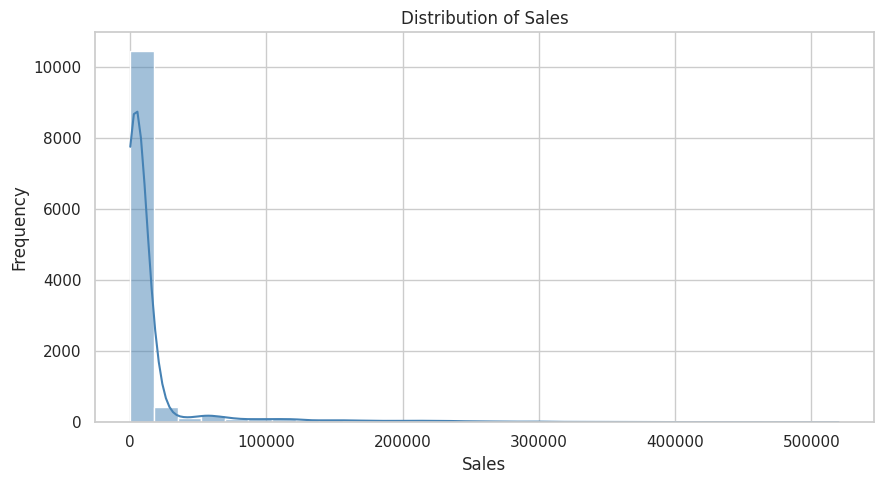

sales: mean=17161.61, median=4331.69, skewness=5.09


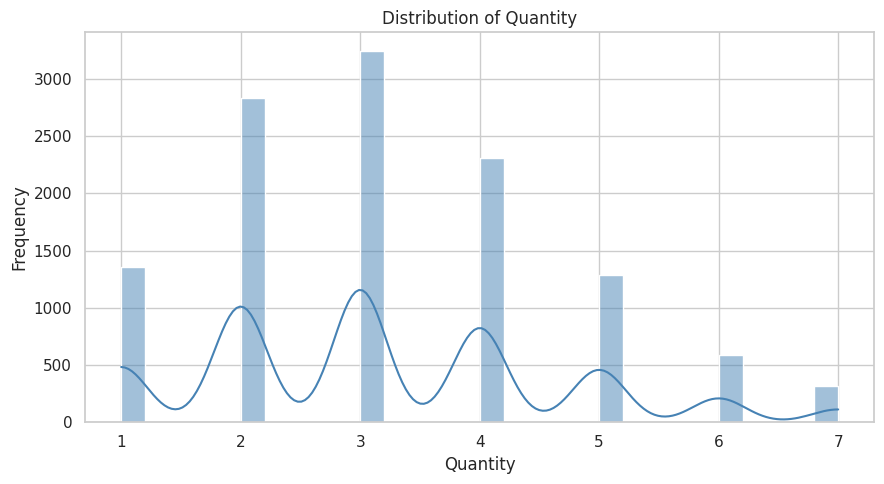

quantity: mean=3.20, median=3.00, skewness=0.53


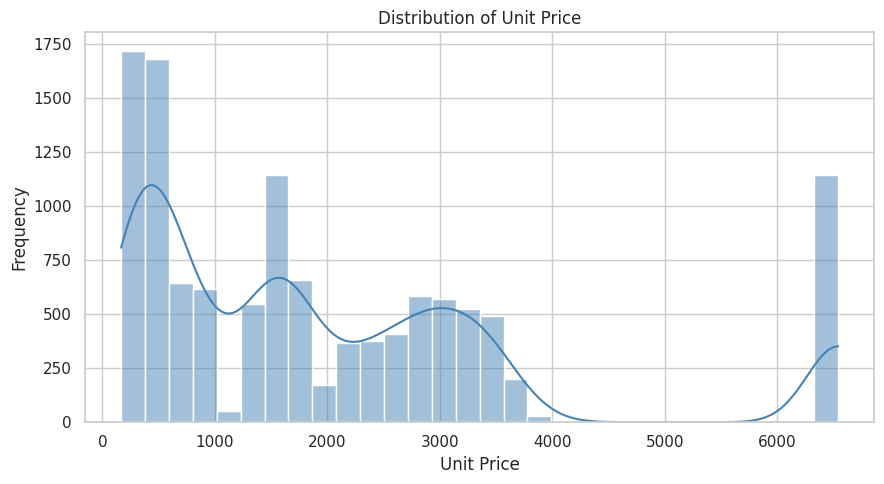

unit_price: mean=2027.86, median=1568.27, skewness=1.30


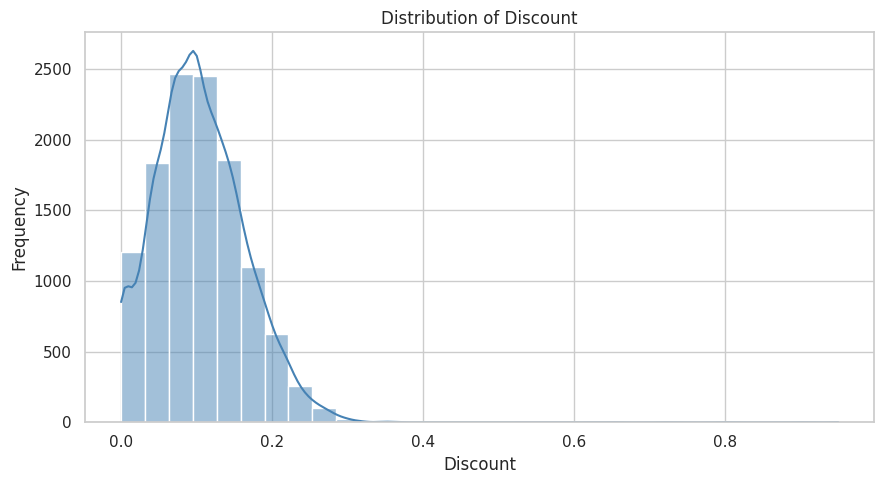

discount: mean=0.10, median=0.10, skewness=1.07


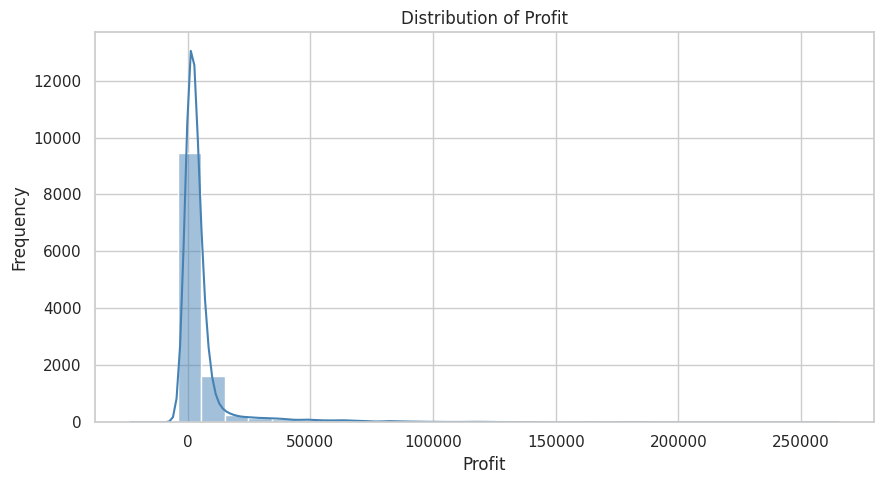

profit: mean=6032.35, median=2107.84, skewness=6.61


In [ ]:

distribution_cols = [
    col for col in ["sales", "quantity", "unit_price", "discount", "profit"]
    if col in df.columns
]

for col in distribution_cols:
    values = df[col].dropna()

    if values.nunique() < 2:
        print(f"Skipping {col}: insufficient variation.")
        continue

    fig, ax = plt.subplots(figsize=(9, 5))

    sns.histplot(
        values,
        bins=30,
        kde=True,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    print(
        f"{col}: mean={values.mean():.2f}, "
        f"median={values.median():.2f}, "
        f"skewness={values.skew():.2f}"
    )

### Chart interpretation — numerical distributions

In this dataset snapshot, **sales** are strongly right-skewed (skewness 5.09); a relatively small number of high-value records pull the mean above the median. **Profit** is also right-skewed (skewness 6.61). This supports reporting medians and quartiles alongside means. The charts describe all order statuses unless otherwise stated, so they should not be read as completed-order-only results.


## 8. Correlation Analysis

Correlation measures the strength and direction of a linear relationship between two numerical variables.

A positive correlation indicates that two variables tend to increase together. A negative correlation indicates that one tends to decrease as the other increases. A correlation near zero indicates a weak linear relationship, although nonlinear relationships may still exist.

A correlation heatmap provides an overview of relationships among numerical variables.


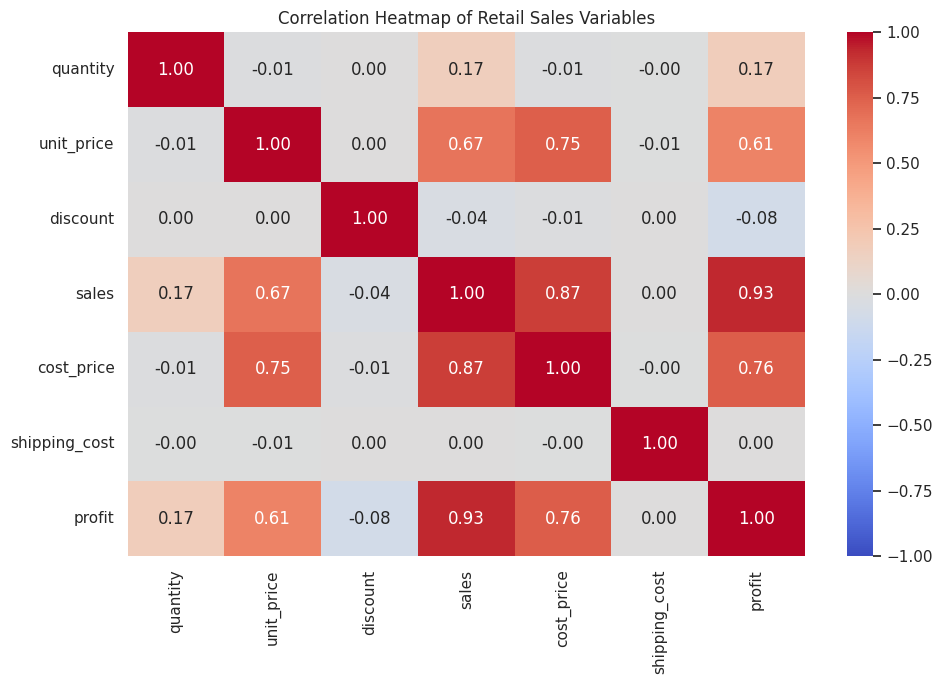

,quantity,unit_price,discount,sales,cost_price,shipping_cost,profit
quantity,1.000,-0.014,0.003,0.166,-0.012,-0.005,0.175
unit_price,-0.014,1.000,0.000,0.670,0.752,-0.006,0.609
discount,0.003,0.000,1.000,-0.037,-0.011,0.001,-0.080
sales,0.166,0.670,-0.037,1.000,0.872,0.002,0.934
cost_price,-0.012,0.752,-0.011,0.872,1.000,-0.001,0.760
shipping_cost,-0.005,-0.006,0.001,0.002,-0.001,1.000,0.001
profit,0.175,0.609,-0.080,0.934,0.760,0.001,1.000


In [ ]:

# Select numerical variables relevant to retail analysis
correlation_candidates = [
    "quantity",
    "unit_price",
    "discount",
    "sales",
    "cost_price",
    "shipping_cost",
    "profit"
]

corr_cols = [col for col in correlation_candidates if col in df.columns]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Retail Sales Variables")
plt.tight_layout()
plt.show()

display(corr_matrix.round(3))

### Chart interpretation — correlation heatmap

The strongest absolute pairwise correlations in the selected numeric fields are **sales vs. profit** (r = 0.93) and **sales vs. cost_price** (r = 0.87). Correlation captures linear association, not causation. The sales field also does not consistently reconcile to the simple calculation `quantity × unit_price` (only 0.2% of rows are within 1 unit), so confirm the source-system sales definition before interpreting these relationships as a financial model.

In [ ]:

# List unique variable pairs, excluding self-correlations
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

correlation_pairs = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
)

correlation_pairs.columns = ["variable_1", "variable_2", "correlation"]

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "absolute_correlation",
    ascending=False
)

display(correlation_pairs.round(3))

,variable_1,variable_2,correlation,absolute_correlation
17,sales,profit,0.934,0.934
15,sales,cost_price,0.872,0.872
19,cost_price,profit,0.760,0.760
8,unit_price,cost_price,0.752,0.752
7,unit_price,sales,0.670,0.670
10,unit_price,profit,0.609,0.609
5,quantity,profit,0.175,0.175
2,quantity,sales,0.166,0.166
14,discount,profit,-0.080,0.080
11,discount,sales,-0.037,0.037



## 9. Sales Distribution and Potential Outliers by Category

Boxplots summarize the median, quartiles, and potential outliers of a numerical variable.

Comparing sales across product categories helps reveal differences in typical transaction values and variability. The same approach can be used to compare regions or sales channels.

A point beyond the whiskers is a potential statistical outlier, not necessarily an incorrect transaction. Large purchases may be legitimate and should not be removed without business justification.

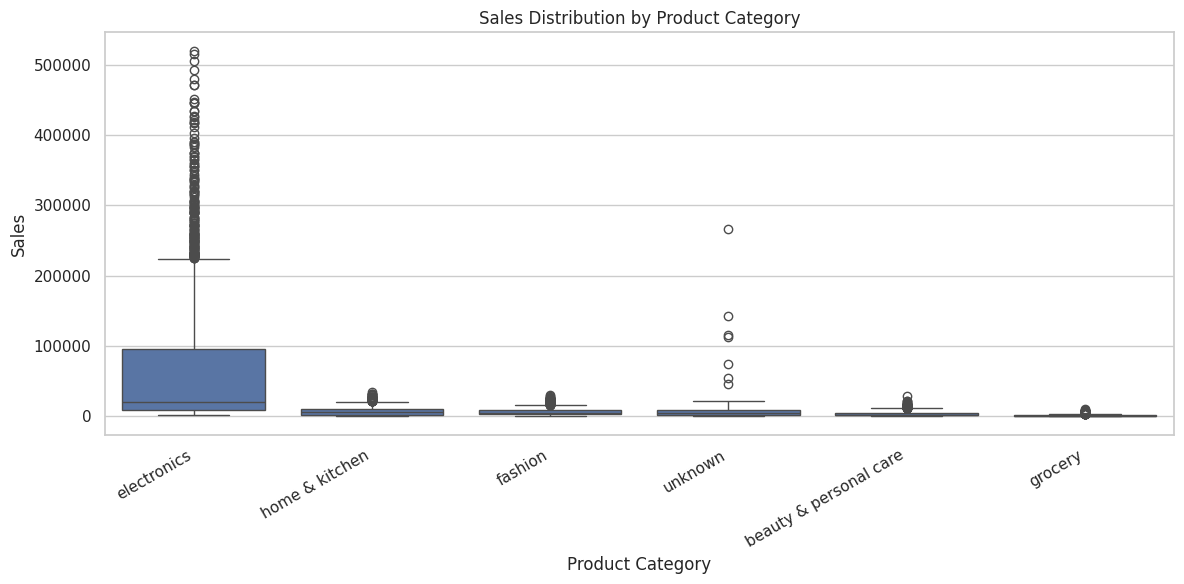

In [ ]:

if {"product_category", "sales"}.issubset(df.columns):
    category_order = (
        df.groupby("product_category")["sales"]
        .median()
        .sort_values(ascending=False)
        .index
    )

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df,
        x="product_category",
        y="sales",
        order=category_order
    )

    plt.title("Sales Distribution by Product Category")
    plt.xlabel("Product Category")
    plt.ylabel("Sales")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns product_category and sales are not available.")

### Chart interpretation — sales by product category

Electronics has the highest median transaction sales and the highest total recorded sales. It represents **77.50%** of total recorded sales while accounting for **19.88%** of rows. Its mean unit price (4,650.77) is much higher than the other categories, which may explain part of the difference. However, the size of the gap is large and transaction-level `sales` frequently differs from `quantity × unit_price`; treat the 77.5% share as a signal to validate, not automatically as expected business performance.

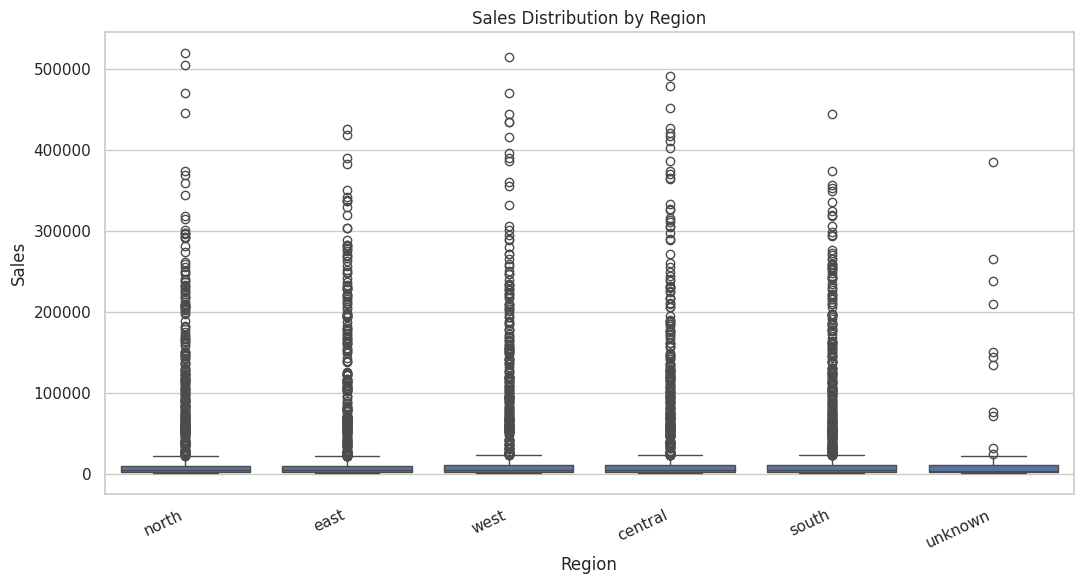

In [ ]:

if {"region", "sales"}.issubset(df.columns):
    plt.figure(figsize=(11, 6))

    sns.boxplot(
        data=df,
        x="region",
        y="sales"
    )

    plt.title("Sales Distribution by Region")
    plt.xlabel("Region")
    plt.ylabel("Sales")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Chart interpretation — sales by region

Among named regions, Central has the highest recorded total (41,479,793.71) and East the lowest (38,866,986.85); their totals are relatively close compared with the separate `unknown` group. There are **144 rows (1.21%)** labelled `unknown`. The store-ID cross-check shows all of these rows' store IDs have a single consistent known-region mapping elsewhere in the data; the added data-quality section quantifies that mapping without overwriting the original values.


## 10. Time-Series Analysis of Monthly Sales

Time-series analysis examines how a variable changes over time.

We will aggregate transaction sales by month and visualize the monthly totals. This can help identify periods of growth, decline, recurring fluctuations, and unusual changes.

Monthly totals represent overall revenue, not necessarily changes in individual customer spending. Transaction counts and average transaction values should also be considered when interpreting the trend.


,month,total_sales,average_transaction_sales,transaction_count
0,2023-01-01,4353957.77,13910.408211,313
1,2023-02-01,3436876.33,11195.036906,307
2,2023-03-01,5962305.88,18122.510274,329
3,2023-04-01,5017452.24,14888.582315,337
4,2023-05-01,4754701.60,14108.906825,337


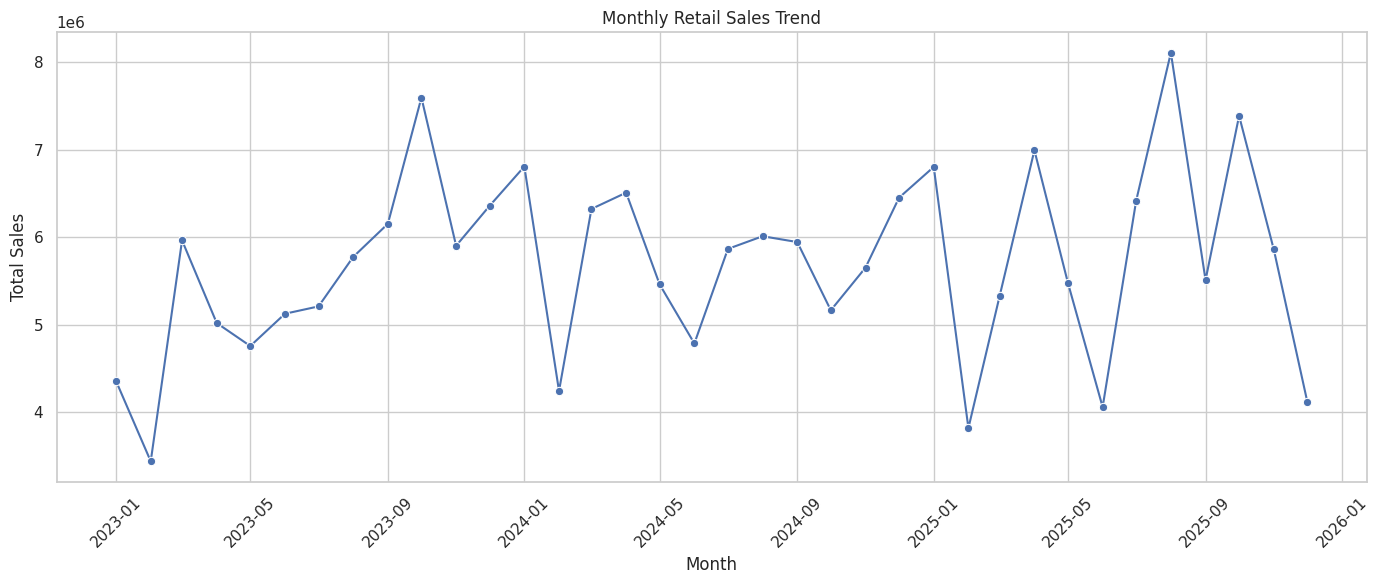

In [ ]:

if {"order_date", "sales"}.issubset(df.columns):
    time_df = df.dropna(subset=["order_date", "sales"]).copy()

    time_df["month"] = (
        time_df["order_date"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    monthly_summary = (
        time_df.groupby("month")
        .agg(
            total_sales=("sales", "sum"),
            average_transaction_sales=("sales", "mean"),
            transaction_count=("sales", "size")
        )
        .reset_index()
        .sort_values("month")
    )

    display(monthly_summary.head())

    fig, ax = plt.subplots(figsize=(14, 6))

    sns.lineplot(
        data=monthly_summary,
        x="month",
        y="total_sales",
        marker="o",
        ax=ax
    )

    ax.set_title("Monthly Retail Sales Trend")
    ax.set_xlabel("Month")
    ax.set_ylabel("Total Sales")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
else:
    print("The dataset needs order_date and sales columns for time-series analysis.")

### Chart interpretation — monthly sales trend

The monthly recorded-sales line reaches its maximum in **August 2025** (8,106,887.18) and minimum in **February 2023** (3,436,876.33). These monthly totals include completed, returned, and cancelled orders. Use the completed-only status comparison before interpreting the trend as realized sales, and investigate whether the peak reflects transaction volume, unusually high-value records, or data-quality issues rather than assuming seasonality.

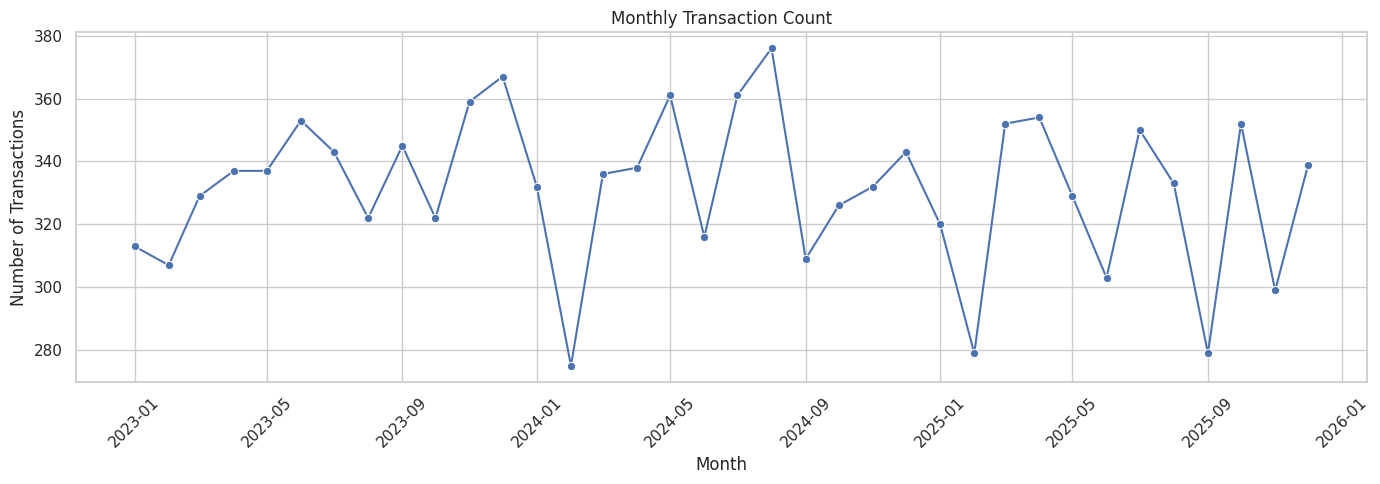

In [ ]:

if "monthly_summary" in globals() and not monthly_summary.empty:
    fig, ax = plt.subplots(figsize=(14, 5))

    sns.lineplot(
        data=monthly_summary,
        x="month",
        y="transaction_count",
        marker="o",
        ax=ax
    )

    ax.set_title("Monthly Transaction Count")
    ax.set_xlabel("Month")
    ax.set_ylabel("Number of Transactions")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

### Chart interpretation — monthly transaction count

The monthly transaction-count chart helps distinguish a sales peak driven by more orders from one driven by larger order values. In this dataset, the highest recorded-sales month is **August 2025** (8,106,887.18) and the lowest is **February 2023** (3,436,876.33). Compare those months' transaction counts and order statuses before attributing the sales difference to demand or seasonality.


### Interpretation of Monthly Trends

Examine the direction of the monthly sales line and identify the highest and lowest months.

Compare monthly sales totals with transaction counts. If both increase, the change may be associated with more transactions. If sales increase while transaction counts remain stable, average transaction value may be contributing to the change.

Do not conclude that the business has a long-term growth trend based on a single peak. Consider the full time period and investigate possible seasonality or unusual events before making recommendations.



## 11. Sales Performance by Business Category

Grouped analysis summarizes data by categories such as product category, region, customer segment, and sales channel.

We will compare total sales, average transaction sales, transaction counts, and total profit. These measures provide complementary views of performance.

Total sales help identify revenue contribution, while average transaction sales describe the typical transaction value. Total profit helps assess financial contribution, provided the profit field is correctly defined in the source dataset.


**Metric note:** Unless a section explicitly filters `order_status`, totals in this section are *recorded sales across all statuses*, not confirmed realized revenue. The notebook separately compares completed orders with returned and cancelled orders.

,product_category,total_sales,average_sales,median_sales,total_profit,transaction_count,sales_share_percent
0,electronics,1.586381e+08,66907.67,19831.76,49414776.39,2371,77.50
1,home & kitchen,1.746905e+07,6984.82,5612.05,8044173.77,2501,8.53
2,fashion,1.631883e+07,6202.52,5172.83,8866790.17,2631,7.97
3,beauty & personal care,7.080977e+06,3806.98,2463.16,3686674.01,1860,3.46
4,grocery,3.747183e+06,1531.96,1066.10,1407490.76,2446,1.83
5,unknown,1.449536e+06,12180.98,4160.78,533917.85,119,0.71


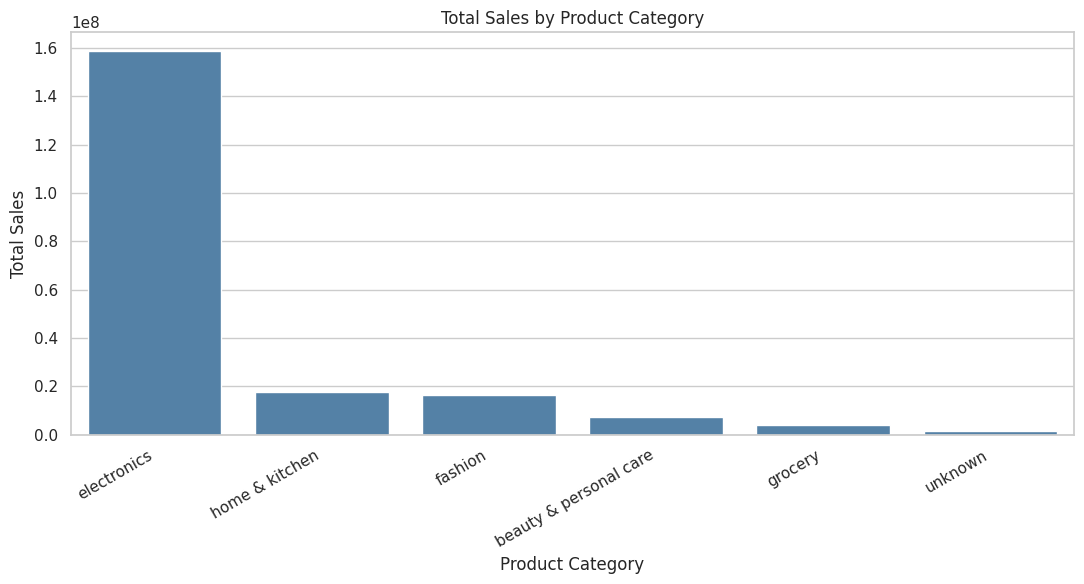

In [ ]:

if "product_category" in df.columns:
    category_summary = (
        df.groupby("product_category", dropna=False)
        .agg(
            total_sales=("sales", "sum"),
            average_sales=("sales", "mean"),
            median_sales=("sales", "median"),
            total_profit=("profit", "sum"),
            transaction_count=("sales", "size")
        )
        .sort_values("total_sales", ascending=False)
        .reset_index()
    )

    category_summary["sales_share_percent"] = (
        category_summary["total_sales"]
        / category_summary["total_sales"].sum()
        * 100
    )

    display(category_summary.round(2))

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=category_summary,
        x="product_category",
        y="total_sales",
        color="steelblue"
    )

    plt.title("Total Sales by Product Category")
    plt.xlabel("Product Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### Chart interpretation — category totals

The recorded-sales ranking is led by Electronics (158,638,076.20), followed by Home & Kitchen (17,469,045.68) and Fashion (16,318,825.99). Electronics' sales share is disproportionately high relative to its transaction count, so check the unit-price and sales-generation logic before using this ranking for assortment or inventory decisions.

,region,total_sales,average_sales,total_profit,transaction_count
0,central,41479793.71,17553.87,14917043.94,2363
1,south,41461498.11,17282.83,14699905.51,2399
2,north,40247434.06,17325.63,13623932.75,2323
3,west,40214746.73,17185.79,14541676.87,2340
4,east,38866986.85,16476.04,13326482.25,2359
5,unknown,2433185.13,16897.12,844781.63,144


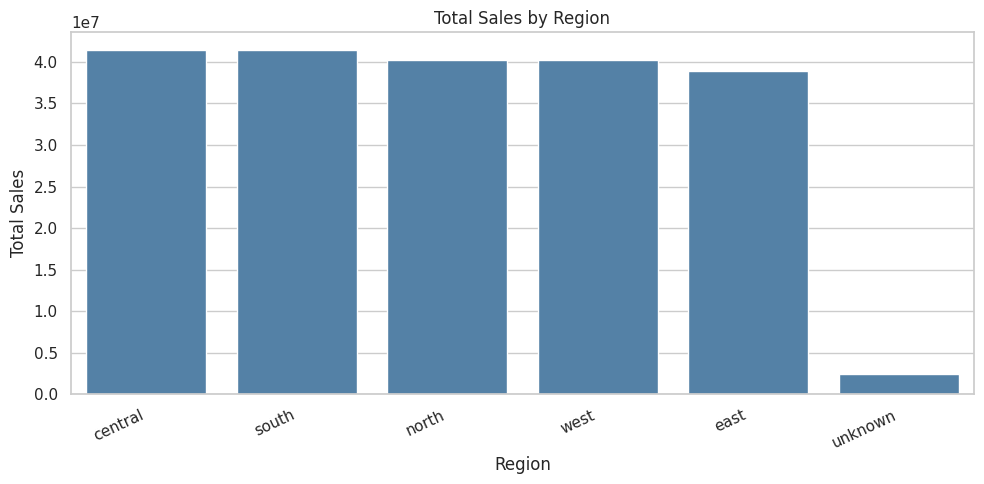

In [ ]:

if "region" in df.columns:
    region_summary = (
        df.groupby("region", dropna=False)
        .agg(
            total_sales=("sales", "sum"),
            average_sales=("sales", "mean"),
            total_profit=("profit", "sum"),
            transaction_count=("sales", "size")
        )
        .sort_values("total_sales", ascending=False)
        .reset_index()
    )

    display(region_summary.round(2))

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=region_summary,
        x="region",
        y="total_sales",
        color="steelblue"
    )

    plt.title("Total Sales by Region")
    plt.xlabel("Region")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Chart interpretation — regional totals

The five named regions range from **38,866,986.85** in East to **41,479,793.71** in Central. The `unknown` group has 144 rows and 2,433,185.13 recorded sales; this should be treated as a data-quality category, not as a real geographic region. Store-ID mapping is examined in the data-quality section below.

In [ ]:

if "sales_channel" in df.columns:
    channel_summary = (
        df.groupby("sales_channel", dropna=False)
        .agg(
            total_sales=("sales", "sum"),
            average_sales=("sales", "mean"),
            total_profit=("profit", "sum"),
            transaction_count=("sales", "size")
        )
        .sort_values("total_sales", ascending=False)
        .reset_index()
    )

    display(channel_summary.round(2))

,sales_channel,total_sales,average_sales,total_profit,transaction_count
0,in-store,1.281274e+08,17384.99,45244327.30,7370
1,online,7.410591e+07,16694.28,25935623.07,4439
2,unknown,2.470379e+06,20759.48,773872.58,119



## 12. Relationships Between Numerical Variables

Scatterplots show the relationship between two numerical variables. Each point represents an observation, making it possible to examine trends, clusters, and unusual transactions.

We will investigate the relationships between quantity and sales, and between discounts and sales.

These charts can help identify associations, but other factors such as unit price, product category, and transaction size may influence the observed patterns. The findings should therefore be treated as exploratory rather than causal.


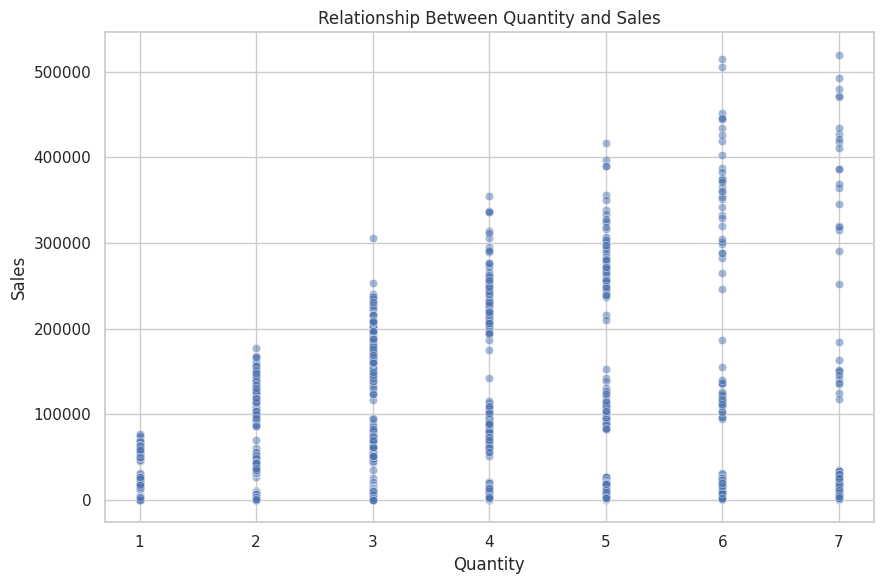

In [ ]:

if {"quantity", "sales"}.issubset(df.columns):
    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x="quantity",
        y="sales",
        alpha=0.5
    )

    plt.title("Relationship Between Quantity and Sales")
    plt.xlabel("Quantity")
    plt.ylabel("Sales")
    plt.tight_layout()
    plt.show()

### Chart interpretation — quantity versus sales

Quantity and recorded sales have a Pearson correlation of **0.17**. The scatter shows wide variation in sales at similar quantities, suggesting unit price and/or other calculation factors matter. Several unusually high sales records should be validated, especially because recorded sales do not reliably equal quantity multiplied by unit price.

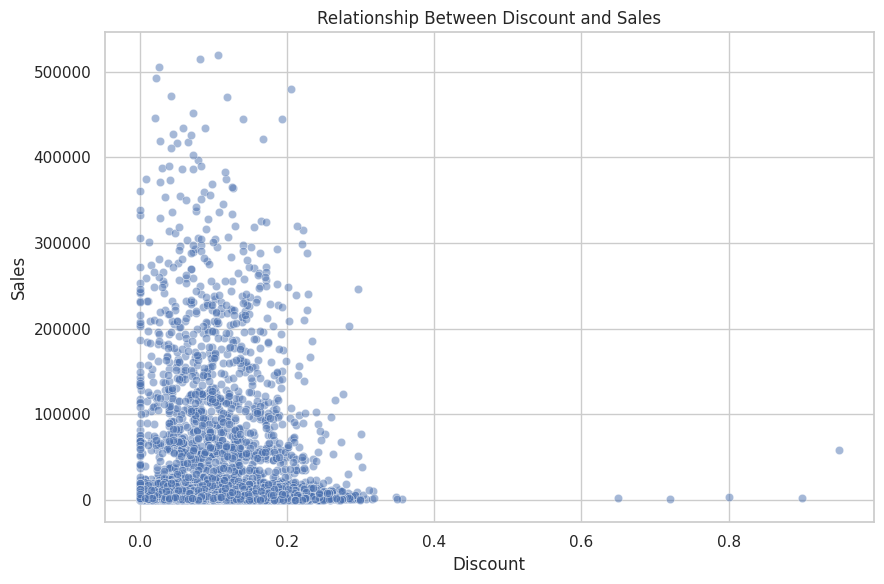

In [ ]:

if {"discount", "sales"}.issubset(df.columns):
    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x="discount",
        y="sales",
        alpha=0.5
    )

    plt.title("Relationship Between Discount and Sales")
    plt.xlabel("Discount")
    plt.ylabel("Sales")
    plt.tight_layout()
    plt.show()

### Chart interpretation — discount versus sales

Discount and recorded sales have a Pearson correlation of **-0.04** in the full dataset. The point cloud is dispersed, so discount alone is not a useful explanation of sales value. This observational relationship does not establish that discounts cause higher or lower sales; compare completed orders and product mix when assessing promotions.


## 13. Discount-Level Performance

Discounts can influence transaction behavior, but higher sales do not automatically imply higher profitability.

To explore promotional performance, we will group transactions into discount bands and compare total sales, average sales, total profit, and transaction counts.

These comparisons are descriptive. Differences between discount groups may reflect product mix, customer behavior, or other factors rather than the effect of discounts alone.

,discount_band,total_sales,average_sales,total_profit,transaction_count
0,No discount,8.278290e+06,21784.97,3300323.74,380
1,Up to 10%,1.055384e+08,18383.28,39662025.61,5741
2,10–20%,8.029671e+07,15859.51,26387356.68,5063
3,20–30%,1.036799e+07,14241.74,2542259.67,728
4,Above 30%,2.222534e+05,13890.84,61857.25,16


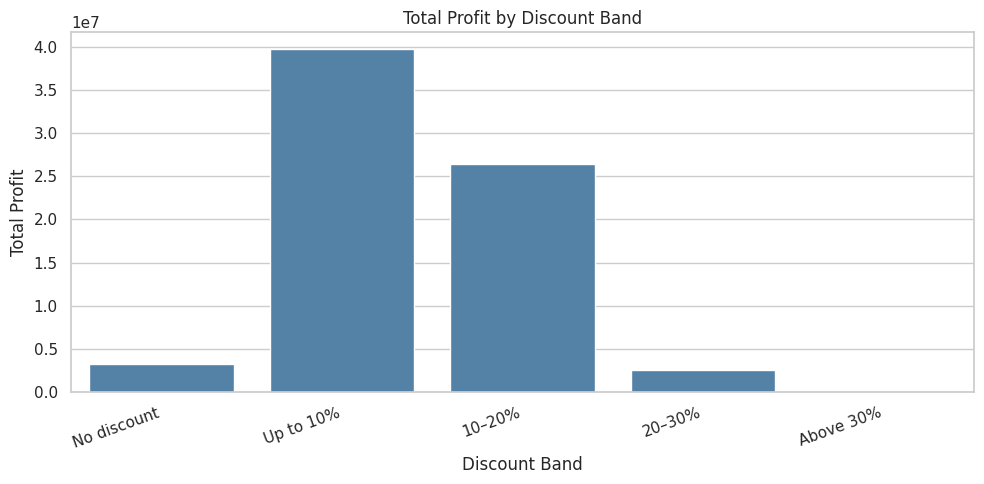

In [ ]:

if {"discount", "sales", "profit"}.issubset(df.columns):
    discount_df = df.copy()

    discount_df["discount_band"] = pd.cut(
        discount_df["discount"],
        bins=[-0.001, 0, 0.10, 0.20, 0.30, 1.0],
        labels=[
            "No discount",
            "Up to 10%",
            "10–20%",
            "20–30%",
            "Above 30%"
        ],
        include_lowest=True
    )

    discount_summary = (
        discount_df.groupby("discount_band", observed=False)
        .agg(
            total_sales=("sales", "sum"),
            average_sales=("sales", "mean"),
            total_profit=("profit", "sum"),
            transaction_count=("sales", "size")
        )
        .reset_index()
    )

    display(discount_summary.round(2))

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=discount_summary,
        x="discount_band",
        y="total_profit",
        color="steelblue"
    )

    plt.title("Total Profit by Discount Band")
    plt.xlabel("Discount Band")
    plt.ylabel("Total Profit")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

### Chart interpretation — profit by discount band

The highest total recorded profit is in the **Up to 10%** band. Total profit is affected by the number and mix of transactions, so compare profit per transaction as well as total profit. Returned and cancelled orders are included in this chart; the status-specific analysis below makes that limitation visible.


### Interpretation of Discount-Level Analysis

Compare revenue and profit across the discount bands, while considering the number of transactions in each group.

A discount band with high total sales but low or negative total profit may warrant closer examination. However, groups with more transactions may naturally have larger totals, so average transaction values and transaction counts should also be considered.

The results can help identify discount levels for further investigation. They should not be used alone to declare a discount policy successful or unsuccessful.


## 14. Order Status and Data-Quality Checks

### Order status: recorded sales are not the same as realized revenue

The file contains **11,928 orders**: 11,231 completed (94.16%), 480 returned (4.02%), and 217 cancelled (1.82%). Since `sales` is populated for all three statuses, unfiltered totals combine completed, returned, and cancelled orders. The completed-only analysis below is a cleaner proxy for completed-order sales, but returned orders may need to be netted out using a business-approved accounting rule; the dataset does not specify that rule.

### Why does Electronics account for 77.5% of recorded sales?

Electronics represents **77.50%** of total recorded sales but only **19.88%** of records. Its mean unit price is **4,650.77**, versus **1,377.14** across non-Electronics records. This higher unit price can explain some of the gap, but it does not by itself establish that the 77.5% share is expected. In this file, only 0.2% of rows have `sales` within 1 unit of `quantity × unit_price`, and Electronics includes repeated high unit-price values and very large sales records. Validate the sales formula, currency/scale, category assignment, and any hidden multipliers or aggregation rules with the dataset owner before treating this share as a business fact.

### Investigating `unknown` region

There are **144 rows (1.21%)** with region set to `unknown`. They span multiple store IDs, but each affected store ID has a consistent region among its other records. The mapping below is a diagnostic inference from the observed store-to-region pattern, not a replacement for authoritative store master data. The raw `region` field remains unchanged.

Recorded totals by order status (not net accounting revenue):


,order_status,order_count,recorded_sales,recorded_profit,average_recorded_sales,order_share_percent
0,cancelled,217,3.980776e+06,1457672.20,18344.59,1.82
1,completed,11231,1.924383e+08,67405573.77,17134.56,94.16
2,returned,480,8.284592e+06,3090576.98,17259.57,4.02


Completed-only orders: 11,231 / 11,928 (94.16%)
Completed-only recorded sales: 192,438,276.84
All-status recorded sales: 204,703,644.59
Returned + cancelled recorded sales: 12,265,367.75


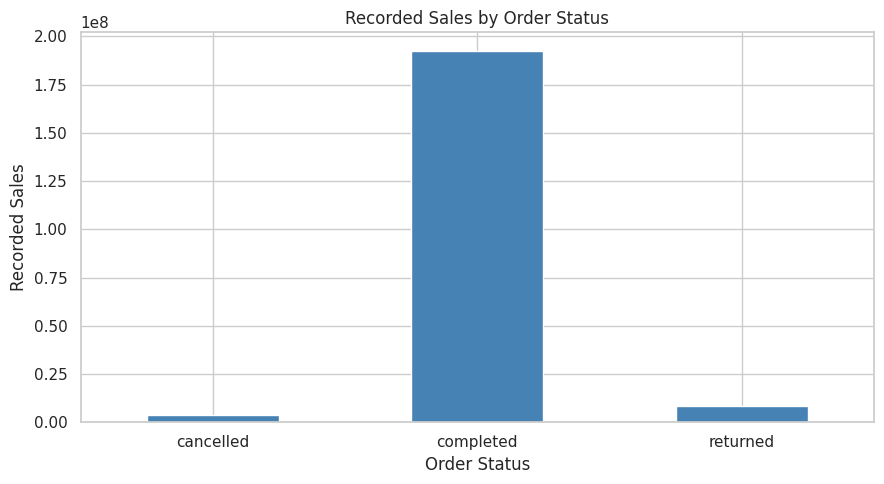

Interpretation: completed orders dominate the count and sales, but returns and cancellations are non-zero. Do not equate all-status sales with realized revenue without a defined treatment for each status.


,store_id,region_inferred_from_store_pattern,rows,recorded_sales
0,ST101,north,9,329708.54
1,ST102,north,7,46986.06
2,ST103,north,10,34978.49
3,ST201,south,9,292605.79
4,ST202,south,9,186182.98
5,ST203,south,8,26035.40
6,ST301,east,6,330196.79
7,ST302,east,9,55752.48
8,ST303,east,16,461869.39
9,ST401,west,11,69017.71


Unknown-region rows with a known store-to-region pattern: 144 / 144.
Action: confirm inferred mappings against an authoritative store master file, then correct upstream source data rather than silently replacing unknown labels in this analysis.
Completed-only category sales and share:


,completed_recorded_sales,share_of_completed_sales_percent
product_category,,
electronics,1.490400e+08,77.45
home & kitchen,1.651519e+07,8.58
fashion,1.525998e+07,7.93
beauty & personal care,6.709979e+06,3.49
grocery,3.499334e+06,1.82
unknown,1.413800e+06,0.73


Electronics share among completed-order sales: 77.45% (compare with 77.50% across all statuses).


In [ ]:
# Status-aware sales comparison and region data-quality diagnostic
status_col = "order_status"
if {status_col, "sales", "profit"}.issubset(df.columns):
    status_summary = (
        df.groupby(status_col, dropna=False)
        .agg(order_count=("order_id", "size"), recorded_sales=("sales", "sum"), recorded_profit=("profit", "sum"), average_recorded_sales=("sales", "mean"))
        .reset_index()
    )
    status_summary["order_share_percent"] = status_summary["order_count"] / len(df) * 100
    print("Recorded totals by order status (not net accounting revenue):")
    display(status_summary.round(2))

    completed_df = df[df[status_col].astype(str).str.lower().eq("completed")].copy()
    print(f"Completed-only orders: {len(completed_df):,} / {len(df):,} ({len(completed_df)/len(df)*100:.2f}%)")
    print(f"Completed-only recorded sales: {completed_df['sales'].sum():,.2f}")
    print(f"All-status recorded sales: {df['sales'].sum():,.2f}")
    print(f"Returned + cancelled recorded sales: {df.loc[df[status_col].astype(str).str.lower().isin(['returned','cancelled']), 'sales'].sum():,.2f}")

    status_sales = status_summary.set_index(status_col)["recorded_sales"]
    ax = status_sales.plot(kind="bar", figsize=(9, 5), color="steelblue")
    ax.set_title("Recorded Sales by Order Status")
    ax.set_xlabel("Order Status")
    ax.set_ylabel("Recorded Sales")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    print("Interpretation: completed orders dominate the count and sales, but returns and cancellations are non-zero. Do not equate all-status sales with realized revenue without a defined treatment for each status.")

# Investigate unknown regions using the stable store_id -> known region pattern.
if {"region", "store_id"}.issubset(df.columns):
    normalized_region = df["region"].astype("string").str.strip().str.lower()
    is_unknown_region = normalized_region.isna() | normalized_region.isin(["unknown", "", "nan", "none"])
    known_rows = df.loc[~is_unknown_region & df["store_id"].notna(), ["store_id", "region"]].copy()
    known_rows["region"] = known_rows["region"].astype(str).str.strip().str.lower()
    store_region_map = known_rows.groupby("store_id")["region"].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    unknown_region_check = df.loc[is_unknown_region, ["store_id", "sales", "order_status"]].copy()
    unknown_region_check["region_inferred_from_store_pattern"] = unknown_region_check["store_id"].map(store_region_map)
    display(unknown_region_check.groupby(["store_id", "region_inferred_from_store_pattern"], dropna=False).agg(rows=("sales", "size"), recorded_sales=("sales", "sum")).reset_index().round(2))
    mappable = unknown_region_check["region_inferred_from_store_pattern"].notna().sum()
    print(f"Unknown-region rows with a known store-to-region pattern: {mappable:,} / {len(unknown_region_check):,}.")
    print("Action: confirm inferred mappings against an authoritative store master file, then correct upstream source data rather than silently replacing unknown labels in this analysis.")

# Compare category mix using completed orders only.
if {"product_category", "sales", "order_status"}.issubset(df.columns):
    completed_category_sales = completed_df.groupby("product_category", dropna=False)["sales"].sum().sort_values(ascending=False)
    completed_category_share = completed_category_sales / completed_category_sales.sum() * 100
    print("Completed-only category sales and share:")
    display(pd.DataFrame({"completed_recorded_sales": completed_category_sales, "share_of_completed_sales_percent": completed_category_share}).round(2))
    if "electronics" in completed_category_share.index:
        print(f"Electronics share among completed-order sales: {completed_category_share['electronics']:.2f}% (compare with {(df.loc[df['product_category'].astype(str).str.lower().eq('electronics'), 'sales'].sum() / df['sales'].sum() * 100):.2f}% across all statuses).")



## 15. Key Findings and Actionable Business Insights

This section translates the statistical analysis into practical business findings.

Each insight should include a measurable result, its business interpretation, and a recommended action. The recommendations must be supported by the observed data rather than assumptions.

We will examine product category performance, regional performance, and discount-level profitability.

In [ ]:

# Insight 1: Product category performance
if "category_summary" in globals() and not category_summary.empty:
    best_category = category_summary.iloc[0]

    print("INSIGHT 1: PRODUCT CATEGORY PERFORMANCE")
    print(
        f"Highest-revenue category: {best_category['product_category']}"
    )
    print(f"Total sales: {best_category['total_sales']:,.2f}")
    print(
        f"Share of total sales: "
        f"{best_category['sales_share_percent']:.2f}%"
    )
    print(
        "Action: Review this category's inventory availability and "
        "profitability before prioritizing additional stock."
    )

# Insight 2: Regional performance
if "region_summary" in globals() and not region_summary.empty:
    best_region = region_summary.iloc[0]
    lowest_region = region_summary.iloc[-1]

    print("\nINSIGHT 2: REGIONAL PERFORMANCE")
    print(
        f"Highest-revenue region: {best_region['region']} "
        f"({best_region['total_sales']:,.2f})"
    )
    print(
        f"Lowest-revenue region: {lowest_region['region']} "
        f"({lowest_region['total_sales']:,.2f})"
    )
    print(
        "Action: Investigate transaction volume, customer demand, "
        "and product mix in lower-revenue regions before changing "
        "regional budgets."
    )

# Insight 3: Discount-level performance
if "discount_summary" in globals() and not discount_summary.empty:
    valid_discount_groups = discount_summary.dropna(
        subset=["total_profit"]
    )

    if not valid_discount_groups.empty:
        best_profit_band = valid_discount_groups.loc[
            valid_discount_groups["total_profit"].idxmax()
        ]

        print("\nINSIGHT 3: DISCOUNT-LEVEL PROFITABILITY")
        print(
            f"Discount band with the highest total profit: "
            f"{best_profit_band['discount_band']}"
        )
        print(f"Total profit: {best_profit_band['total_profit']:,.2f}")
        print(
            f"Transaction count: "
            f"{best_profit_band['transaction_count']:,}"
        )
        print(
            "Action: Compare profit per transaction and transaction "
            "volume across discount bands before revising promotional "
            "policies."
        )

# Optional Insight 4: Monthly sales
if "monthly_summary" in globals() and not monthly_summary.empty:
    best_month = monthly_summary.loc[
        monthly_summary["total_sales"].idxmax()
    ]

    print("\nINSIGHT 4: MONTHLY SALES")
    print(f"Highest-sales month: {best_month['month'].strftime('%B %Y')}")
    print(f"Monthly sales: {best_month['total_sales']:,.2f}")
    print(
        "Action: Investigate the products, channels, and transaction "
        "volume associated with this peak before planning future campaigns."
    )

INSIGHT 1: PRODUCT CATEGORY PERFORMANCE
Highest-revenue category: electronics
Total sales: 158,638,076.20
Share of total sales: 77.50%
Action: Review this category's inventory availability and profitability before prioritizing additional stock.

INSIGHT 2: REGIONAL PERFORMANCE
Highest-revenue region: central (41,479,793.71)
Lowest-revenue region: unknown (2,433,185.13)
Action: Investigate transaction volume, customer demand, and product mix in lower-revenue regions before changing regional budgets.

INSIGHT 3: DISCOUNT-LEVEL PROFITABILITY
Discount band with the highest total profit: Up to 10%
Total profit: 39,662,025.61
Transaction count: 5,741
Action: Compare profit per transaction and transaction volume across discount bands before revising promotional policies.

INSIGHT 4: MONTHLY SALES
Highest-sales month: August 2025
Monthly sales: 8,106,887.18
Action: Investigate the products, channels, and transaction volume associated with this peak before planning future campaigns.


In [ ]:

OUTPUT_DIR = DATA_PATH.parent / "EDA_Outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save descriptive statistics
numeric_stats.to_csv(OUTPUT_DIR / "descriptive_statistics.csv")

# Save correlation matrix
corr_matrix.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

# Save grouped summaries when available
if "category_summary" in globals():
    category_summary.to_csv(
        OUTPUT_DIR / "category_sales_summary.csv",
        index=False
    )

if "region_summary" in globals():
    region_summary.to_csv(
        OUTPUT_DIR / "regional_sales_summary.csv",
        index=False
    )

if "monthly_summary" in globals():
    monthly_summary.to_csv(
        OUTPUT_DIR / "monthly_sales_summary.csv",
        index=False
    )

if "discount_summary" in globals():
    discount_summary.to_csv(
        OUTPUT_DIR / "discount_performance_summary.csv",
        index=False
    )

print("EDA summary tables exported to:", OUTPUT_DIR)


EDA summary tables exported to: /content/drive/MyDrive/Week2Assign/EDA_Outputs


## 16. Conclusion and Practical Recommendations

The following summary is generated from the loaded dataset and grouped results so that the conclusions remain tied to the actual data. Treat these as descriptive findings, not causal explanations.

Recommended follow-up actions:
- Validate how returned and cancelled orders should be represented before using recorded sales as realized revenue.
- Investigate the highest- and lowest-performing product categories and regions alongside transaction counts and profit.
- Review discount-band profit per transaction as well as total profit before changing promotional policy.
- Investigate monthly peaks and troughs using product, channel, promotion, and order-status detail before planning inventory or campaigns.
- Check unusually large or negative profit records against source-system rules; statistical outliers are not automatically data errors.

**Limitation:** This EDA describes observed patterns. It does not establish that discounts, regions, or product categories cause changes in sales or profit.


In [ ]:
# Final data-supported summary (computed from the results above)
print("FINAL EDA SUMMARY")
print(f"Dataset size: {len(df):,} rows × {df.shape[1]} columns.")
print(f"Date coverage: {df['order_date'].min().date()} to {df['order_date'].max().date()}"
      if "order_date" in df.columns and df["order_date"].notna().any()
      else "Date coverage: no valid order_date values available.")

if "product_category" in df.columns and {"sales", "profit"}.issubset(df.columns):
    valid_categories = category_summary.dropna(subset=["total_sales"])
    if not valid_categories.empty:
        top = valid_categories.iloc[0]
        print(f"Top category by recorded total sales: {top['product_category']} "
              f"({top['total_sales']:,.2f}; {top['sales_share_percent']:.1f}% of category totals).")

if "region" in df.columns and {"sales", "profit"}.issubset(df.columns):
    valid_regions = region_summary.dropna(subset=["total_sales"])
    if not valid_regions.empty:
        top_r = valid_regions.iloc[0]
        low_r = valid_regions.iloc[-1]
        print(f"Regional recorded sales range: {low_r['region']} "
              f"({low_r['total_sales']:,.2f}) to {top_r['region']} ({top_r['total_sales']:,.2f}).")

if "order_status" in df.columns:
    status_counts = df["order_status"].value_counts(dropna=False)
    print("Order-status counts:", status_counts.to_dict())
    print("Interpretation caution: aggregate sales above include all order statuses unless explicitly filtered.")
    if "completed" in status_counts.index:
        completed_sales = df.loc[df["order_status"].astype(str).str.lower().eq("completed"), "sales"].sum()
        print(f"Completed-only recorded sales: {completed_sales:,.2f}.")

if "monthly_summary" in globals() and not monthly_summary.empty:
    high = monthly_summary.loc[monthly_summary["total_sales"].idxmax()]
    low = monthly_summary.loc[monthly_summary["total_sales"].idxmin()]
    print(f"Highest recorded-sales month: {high['month']:%B %Y} ({high['total_sales']:,.2f}).")
    print(f"Lowest recorded-sales month: {low['month']:%B %Y} ({low['total_sales']:,.2f}).")

print("\nUsing these summaries as leads for investigation; they are descriptive.")


FINAL EDA SUMMARY
Dataset size: 11,928 rows × 21 columns.
Date coverage: 2023-01-01 to 2025-12-31
Top category by recorded total sales: electronics (158,638,076.20; 77.5% of category totals).
Regional recorded sales range: unknown (2,433,185.13) to central (41,479,793.71).
Order-status counts: {'completed': 11231, 'returned': 480, 'cancelled': 217}
Interpretation caution: aggregate sales above include all order statuses unless explicitly filtered.
Completed-only recorded sales: 192,438,276.84.
Highest recorded-sales month: August 2025 (8,106,887.18).
Lowest recorded-sales month: February 2023 (3,436,876.33).

Using these summaries as leads for investigation; they are descriptive.
